# temperature (meteo) : extraction et prevision

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import periodogram
from statsmodels.tsa.stattools import acf
from statsmodels.tsa.tsatools import detrend
from statsmodels.tsa.seasonal import MSTL

import sys
sys.path.append("..")
from adapt_utils import sliding_window, predict, courbe_apprentissage, courbe_melange, comparer_adapt, barres_adapt

/Users/arnaudgrassian/Downloads/stage_recherche/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


In [2]:
city = "Vancouver"

df = pd.read_csv("../../data/meteo/temperature.csv", parse_dates=["datetime"])
serie = df.set_index("datetime")[city] - 273.15
serie = serie.interpolate().dropna()

temp = serie.to_numpy()
print(len(temp), "points de", serie.index[0], "a", serie.index[-1])
print("min/moy/max :", round(temp.min(), 1), round(temp.mean(), 1), round(temp.max(), 1))

45252 points de 2012-10-01 13:00:00 a 2017-11-30 00:00:00
min/moy/max : -28.0 10.8 33.9


## 1. visualisation

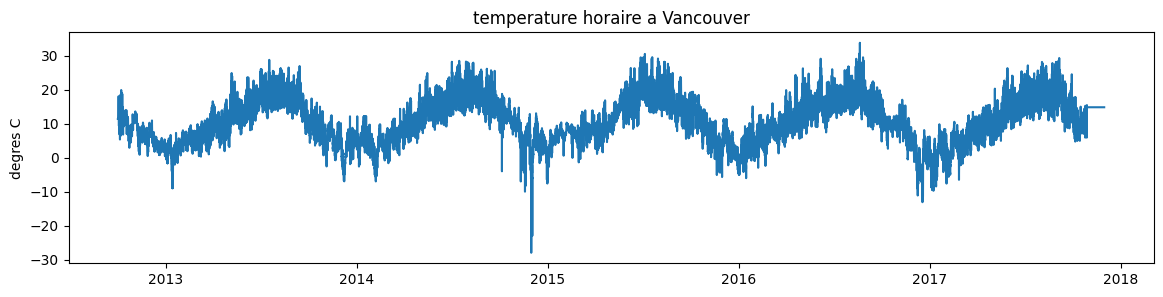

In [3]:
plt.figure(figsize=(14, 3))
plt.plot(serie)
plt.title(f"temperature horaire a {city}")
plt.ylabel("degres C")
plt.show()

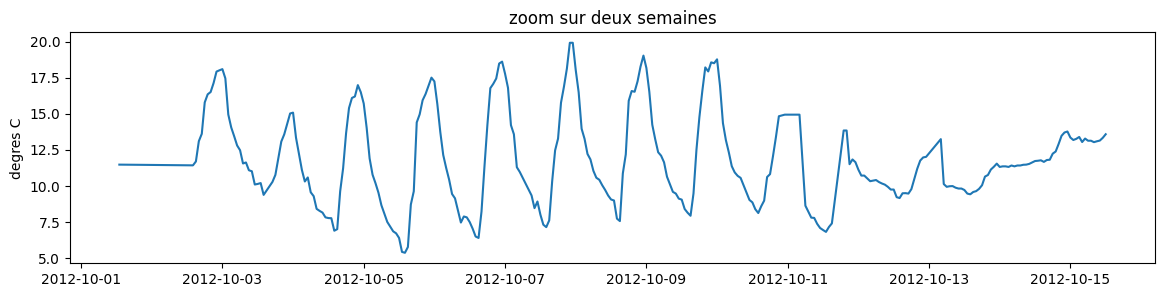

In [4]:
plt.figure(figsize=(14, 3))
plt.plot(serie.iloc[:24 * 14])
plt.title("zoom sur deux semaines")
plt.ylabel("degres C")
plt.show()

## 2. tendance (detrend)

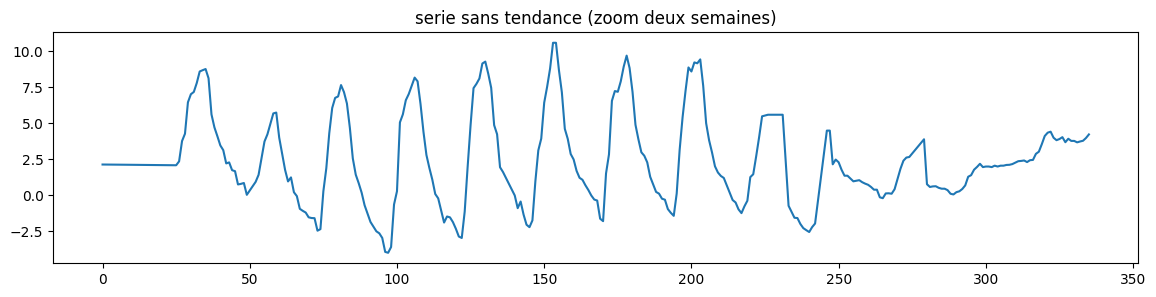

In [5]:
temp_sans_tendance = detrend(temp, order=1)

plt.figure(figsize=(14, 3))
plt.plot(temp_sans_tendance[:24 * 14])
plt.title("serie sans tendance (zoom deux semaines)")
plt.show()

## 3. periode (ACF)

on calcule l'ACF sur le signal detendance

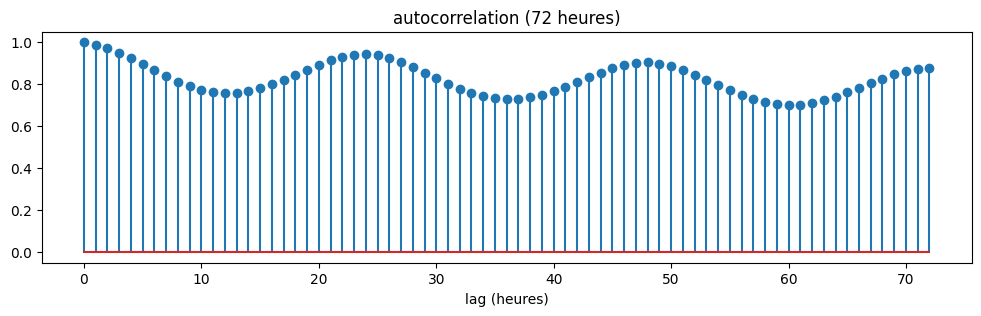

In [6]:
acf_values = acf(temp_sans_tendance, nlags=72)

plt.figure(figsize=(12, 3))
plt.stem(acf_values)
plt.title("autocorrelation (72 heures)")
plt.xlabel("lag (heures)")
plt.show()

## 4. periodogramme

In [7]:
f, power = periodogram(temp_sans_tendance)
periodes = 1 / f[1:]
puissance = power[1:]

ordre = np.argsort(puissance)[::-1]
periodes_detectees = []
for i in ordre:
    p = periodes[i]
    if all(not (0.6 < p / autre < 1.6) for autre in periodes_detectees):
        periodes_detectees.append(p)
    if len(periodes_detectees) == 2:
        break
periodes_detectees = sorted(int(round(p)) for p in periodes_detectees)
print("periodes detectees :", periodes_detectees, "heures")

periodes detectees : [24, 9050] heures


## 5. extraction (STL)

In [8]:
from series_utils import estimate_period

from scipy.signal import find_peaks
from statsmodels.tsa.seasonal import STL

#affichage de la période, de la pente, de l'amplitude et du bruit
period = estimate_period(temp)
res = STL(temp, period=period, robust=True).fit()
pente=np.polyfit(np.arange(len(temp)), res.trend, 1)[0]
amplitude = (res.seasonal.max() - res.seasonal.min()) / 2
bruit = np.nanstd(res.resid)
print(f"periode : {period} heures, pente : {pente:.3f}, amplitude : {amplitude:.3f}, bruit : {bruit:.3f}")

periode : 24 heures, pente : 0.000, amplitude : 15.167, bruit : 1.233


## 6. extraction rapide : cycle journalier (STL)


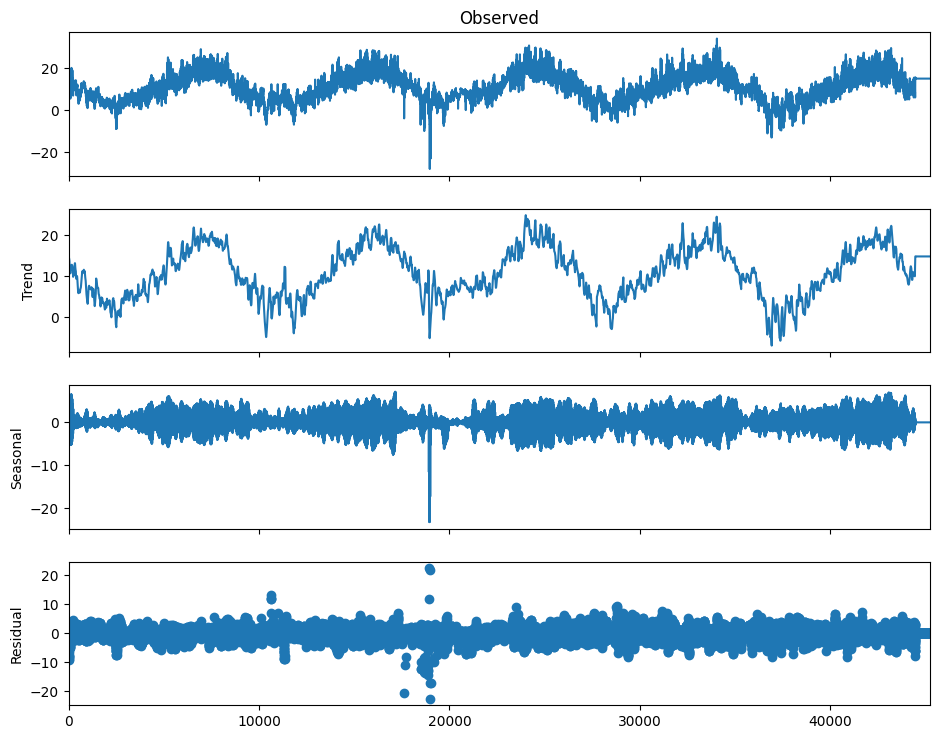

In [9]:
periode_jour = periodes_detectees[0]
res_stl = STL(temp, period=periode_jour, robust=True).fit()

fig = res_stl.plot()
fig.set_size_inches(10, 8)
plt.show()

## 7. prevision : villes source vers ville cible

In [10]:
def temperature_ville(ville):
    s = df.set_index("datetime")[ville] - 273.15
    return s.interpolate().dropna().to_numpy()

source_villes = ["Seattle", "Portland", "San Francisco", "Los Angeles"]
ville_cible = "Jerusalem"
window_size = 24
horizon = 24

Xs_train_list, ys_train_list, Xs_test_list, ys_test_list = [], [], [], []
for v in source_villes:
    X, y = sliding_window(temperature_ville(v), window_size, horizon)
    s = int(len(X) * 0.8)
    Xs_train_list.append(X[:s]); ys_train_list.append(y[:s])
    Xs_test_list.append(X[s:]); ys_test_list.append(y[s:])
Xs_train = np.vstack(Xs_train_list); ys_train = np.concatenate(ys_train_list)
Xs_test = np.vstack(Xs_test_list); ys_test = np.concatenate(ys_test_list)

Xc, yc = sliding_window(temperature_ville(ville_cible), window_size, horizon)
split_c = int(len(Xc) * 0.8)
Xc_train, yc_train, Xc_test, yc_test = Xc[:split_c], yc[:split_c], Xc[split_c:], yc[split_c:]

r_source_source = predict("forecast", Xs_train, ys_train, Xs_test, ys_test)
r_source_cible = predict("forecast", Xs_train, ys_train, Xc_test, yc_test)
print("source -> source :", {k: round(v, 3) for k, v in r_source_source.items()})
print("source -> cible  :", {k: round(v, 3) for k, v in r_source_cible.items()})

source -> source : {'mse': 6.652, 'r2': 0.888}
source -> cible  : {'mse': 4.469, 'r2': 0.893}


## 8. combien de donnees cible pour un bon modele

on part du modele entraine sur la source seule, et on ajoute des donnees cible a l'entrainement, en mesurant le R2 sur le test cible.

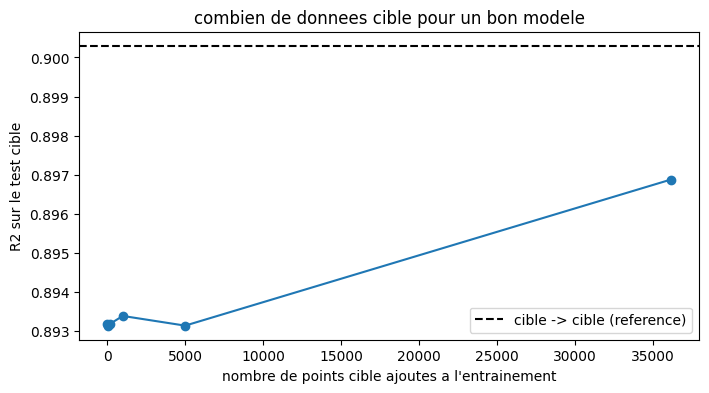

In [11]:
r_cible_ref = predict("forecast", Xc_train, yc_train, Xc_test, yc_test)

n_values = [0, 50, 200, 1000, 5000, len(Xc_train)]
r2_courbe = []
for n in n_values:
    if n == 0:
        X_train, y_train = Xs_train, ys_train
    else:
        X_train = np.vstack([Xs_train, Xc_train[:n]])
        y_train = np.concatenate([ys_train, yc_train[:n]])
    r2_courbe.append(predict("forecast", X_train, y_train, Xc_test, yc_test)["r2"])

plt.figure(figsize=(8, 4))
plt.plot(n_values, r2_courbe, marker="o")
plt.axhline(r_cible_ref["r2"], color="k", linestyle="--", label="cible -> cible (reference)")
plt.xlabel("nombre de points cible ajoutes a l'entrainement")
plt.ylabel("R2 sur le test cible")
plt.title("combien de donnees cible pour un bon modele")
plt.legend()
plt.show()

## 9. courbes d'apprentissage separees : serie brute (source et cible)

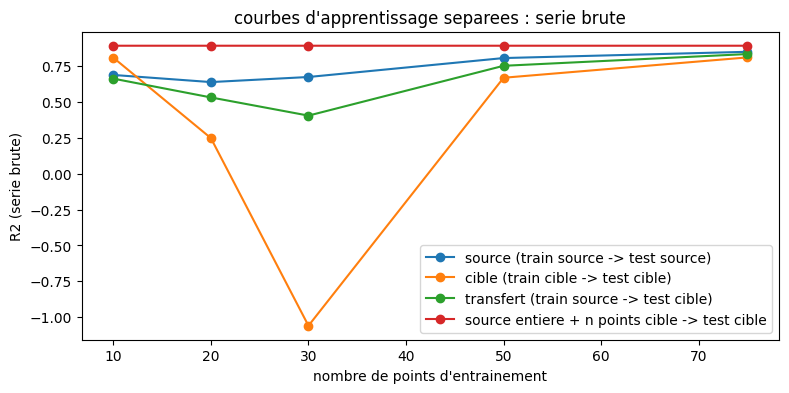

In [12]:
n_values = [10, 20, 30, 50, 75]
ns_source, r2_source = courbe_apprentissage(Xs_train, ys_train, Xs_test, ys_test, "forecast", n_values)
ns_cible, r2_cible = courbe_apprentissage(Xc_train, yc_train, Xc_test, yc_test, "forecast", n_values)

ns_transfert, r2_transfert = courbe_apprentissage(Xs_train, ys_train, Xc_test, yc_test, "forecast", n_values)

ns_melange, r2_melange = courbe_melange(Xs_train, ys_train, Xc_train, yc_train, Xc_test, yc_test, "forecast", n_values)

plt.figure(figsize=(9, 4))
plt.plot(ns_source, r2_source, marker="o", label="source (train source -> test source)")
plt.plot(ns_cible, r2_cible, marker="o", label="cible (train cible -> test cible)")
plt.plot(ns_transfert, r2_transfert, marker="o", label="transfert (train source -> test cible)")
plt.plot(ns_melange, r2_melange, marker="o", label="source entiere + n points cible -> test cible")
plt.xlabel("nombre de points d'entrainement")
plt.ylabel("R2 (serie brute)")
plt.title("courbes d'apprentissage separees : serie brute")
plt.legend()
plt.show()

## 10. prevision de la serie desaisonnalisee (T+N, MSTL)

In [13]:
sigma_bruit = {}

def serie_TN(ville):
    temp = temperature_ville(ville)
    res = MSTL(temp, periods=(24, 8766), stl_kwargs=dict(seasonal_jump=24, trend_jump=24, low_pass_jump=24)).fit()
    sigma_bruit[ville] = np.nanstd(res.resid)
    return temp - np.asarray(res.seasonal).sum(axis=1)

horizon_residu = 24

Xrs_tr_list, yrs_tr_list, Xrs_te_list, yrs_te_list = [], [], [], []
for v in source_villes:
    X, y = sliding_window(serie_TN(v), window_size, horizon_residu)
    s = int(len(X) * 0.8)
    Xrs_tr_list.append(X[:s]); yrs_tr_list.append(y[:s])
    Xrs_te_list.append(X[s:]); yrs_te_list.append(y[s:])
Xrs_train = np.vstack(Xrs_tr_list); yrs_train = np.concatenate(yrs_tr_list)
Xrs_test = np.vstack(Xrs_te_list); yrs_test = np.concatenate(yrs_te_list)

Xrc, yrc = sliding_window(serie_TN(ville_cible), window_size, horizon_residu)
split_rc = int(len(Xrc) * 0.8)
Xrc_train, yrc_train, Xrc_test, yrc_test = Xrc[:split_rc], yrc[:split_rc], Xrc[split_rc:], yrc[split_rc:]

r_res_ss = predict("forecast", Xrs_train, yrs_train, Xrs_test, yrs_test)
r_res_sc = predict("forecast", Xrs_train, yrs_train, Xrc_test, yrc_test)
print("T+N source -> source :", {k: round(v, 3) for k, v in r_res_ss.items()})
print("T+N source -> cible  :", {k: round(v, 3) for k, v in r_res_sc.items()})

T+N source -> source : {'mse': 2.592, 'r2': 0.843}
T+N source -> cible  : {'mse': 2.694, 'r2': -0.013}


## 11. serie desaisonnalisee (T+N) : combien de donnees cible pour un bon modele


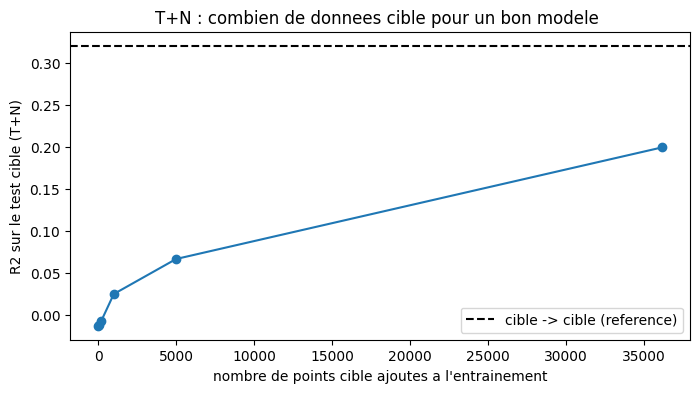

In [14]:
r_res_ref = predict("forecast", Xrc_train, yrc_train, Xrc_test, yrc_test)

n_values_r = [0, 50, 200, 1000, 5000, len(Xrc_train)]
r2_courbe_r = []
for n in n_values_r:
    if n == 0:
        X_train, y_train = Xrs_train, yrs_train
    else:
        X_train = np.vstack([Xrs_train, Xrc_train[:n]])
        y_train = np.concatenate([yrs_train, yrc_train[:n]])
    r2_courbe_r.append(predict("forecast", X_train, y_train, Xrc_test, yrc_test)["r2"])

plt.figure(figsize=(8, 4))
plt.plot(n_values_r, r2_courbe_r, marker="o")
plt.axhline(r_res_ref["r2"], color="k", linestyle="--", label="cible -> cible (reference)")
plt.xlabel("nombre de points cible ajoutes a l'entrainement")
plt.ylabel("R2 sur le test cible (T+N)")
plt.title("T+N : combien de donnees cible pour un bon modele ")
plt.legend()
plt.show()

## 12. courbes d'apprentissage separees : T+N (source et cible)


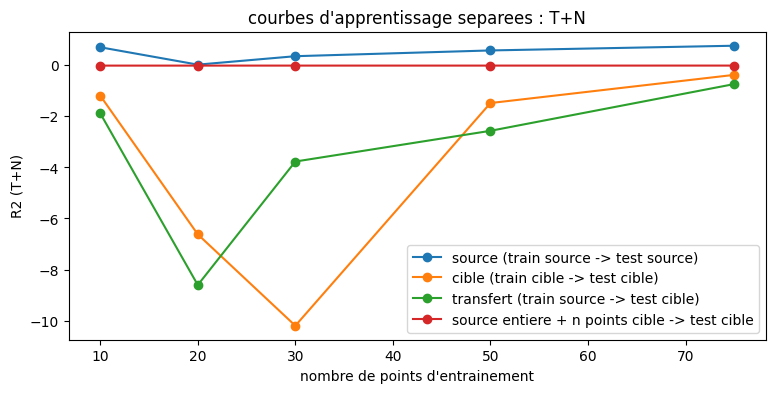

In [15]:
ns_source, r2_source = courbe_apprentissage(Xrs_train, yrs_train, Xrs_test, yrs_test, "forecast", n_values)
ns_cible, r2_cible = courbe_apprentissage(Xrc_train, yrc_train, Xrc_test, yrc_test, "forecast", n_values)

ns_transfert, r2_transfert = courbe_apprentissage(Xrs_train, yrs_train, Xrc_test, yrc_test, "forecast", n_values)

ns_melange, r2_melange = courbe_melange(Xrs_train, yrs_train, Xrc_train, yrc_train, Xrc_test, yrc_test, "forecast", n_values)

plt.figure(figsize=(9, 4))
plt.plot(ns_source, r2_source, marker="o", label="source (train source -> test source)")
plt.plot(ns_cible, r2_cible, marker="o", label="cible (train cible -> test cible)")
plt.plot(ns_transfert, r2_transfert, marker="o", label="transfert (train source -> test cible)")
plt.plot(ns_melange, r2_melange, marker="o", label="source entiere + n points cible -> test cible")
plt.xlabel("nombre de points d'entrainement")
plt.ylabel("R2 (T+N)")
plt.title("courbes d'apprentissage separees : T+N")
plt.legend()
plt.show()

## 13. performances par ville source

deux facons de mesurer la performance par ville. d'abord un seul modele partage, entraine sur toutes les villes source a la fois puis evalue ville par ville : cela mesure ce que vaut un modele commun. ensuite un modele propre a chaque ville, entraine et teste sur la meme ville seule.

temperature brute (modele partage) : R2 par ville source
  Seattle : 0.855
  Portland : 0.862
  San Francisco : 0.879
  Los Angeles : 0.855
cible (Jerusalem) : 0.893


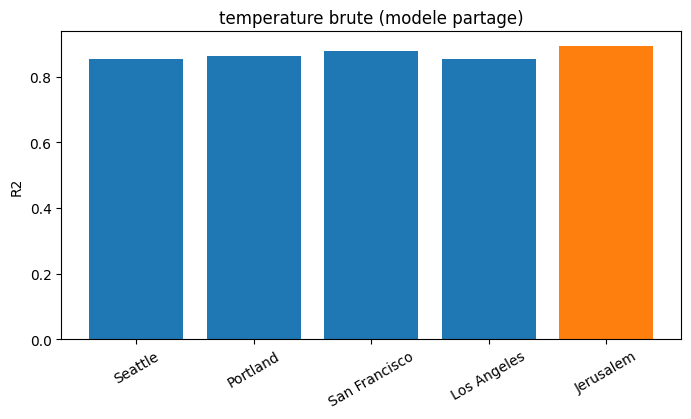

In [16]:
def barres_par_ville(X_train, y_train, test_X_list, test_y_list, X_cible, y_cible, titre):
    valeurs = []
    print(titre, ": R2 par ville source")
    for k, ville in enumerate(source_villes):
        r2 = predict("forecast", X_train, y_train, test_X_list[k], test_y_list[k])["r2"]
        valeurs.append(r2)
        print(f"  {ville} : {round(r2, 3)}")
    r2_cible = predict("forecast", X_train, y_train, X_cible, y_cible)["r2"]
    print(f"cible ({ville_cible}) : {round(r2_cible, 3)}")

    noms = source_villes + [ville_cible]
    couleurs = ["tab:blue"] * len(source_villes) + ["tab:orange"]
    plt.figure(figsize=(8, 4))
    plt.bar(noms, valeurs + [r2_cible], color=couleurs)
    plt.ylabel("R2")
    plt.title(titre)
    plt.xticks(rotation=30)
    plt.show()

barres_par_ville(Xs_train, ys_train, Xs_test_list, ys_test_list, Xc_test, yc_test, "temperature brute (modele partage)")

serie T+N (modele partage) : R2 par ville source
  Seattle : 0.341
  Portland : 0.392
  San Francisco : 0.787
  Los Angeles : 0.468
cible (Jerusalem) : -0.013


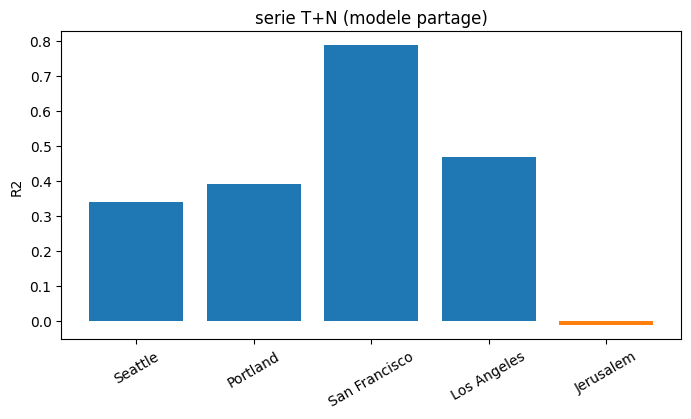

In [17]:
barres_par_ville(Xrs_train, yrs_train, Xrs_te_list, yrs_te_list, Xrc_test, yrc_test, "serie T+N (modele partage)")

temperature brute (un modele par ville) : R2 par ville (un modele par ville)
  Seattle : 0.857
  Portland : 0.862
  San Francisco : 0.876
  Los Angeles : 0.859
cible (Jerusalem) : 0.9


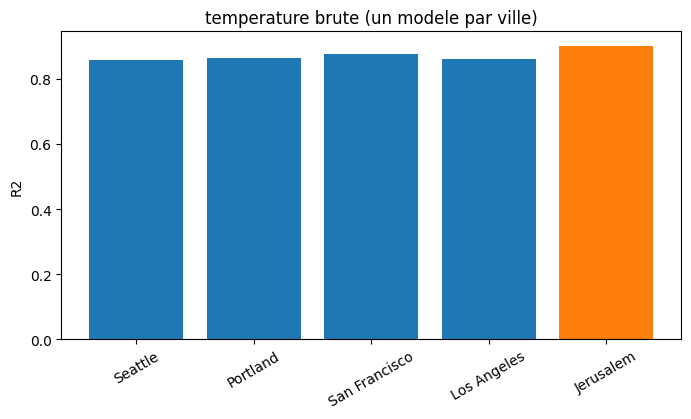

In [18]:
def barres_par_ville_propre(train_X, train_y, test_X, test_y, Xc_tr, yc_tr, Xc_te, yc_te, titre):
    valeurs = []
    print(titre, ": R2 par ville (un modele par ville)")
    for k, ville in enumerate(source_villes):
        r2 = predict("forecast", train_X[k], train_y[k], test_X[k], test_y[k])["r2"]
        valeurs.append(r2)
        print(f"  {ville} : {round(r2, 3)}")
    r2_cible = predict("forecast", Xc_tr, yc_tr, Xc_te, yc_te)["r2"]
    print(f"cible ({ville_cible}) : {round(r2_cible, 3)}")

    noms = source_villes + [ville_cible]
    couleurs = ["tab:blue"] * len(source_villes) + ["tab:orange"]
    plt.figure(figsize=(8, 4))
    plt.bar(noms, valeurs + [r2_cible], color=couleurs)
    plt.ylabel("R2")
    plt.title(titre)
    plt.xticks(rotation=30)
    plt.show()

barres_par_ville_propre(Xs_train_list, ys_train_list, Xs_test_list, ys_test_list, Xc_train, yc_train, Xc_test, yc_test, "temperature brute (un modele par ville)")

serie T+N (un modele par ville) : R2 par ville (un modele par ville)
  Seattle : 0.412
  Portland : 0.447
  San Francisco : 0.766
  Los Angeles : 0.557
cible (Jerusalem) : 0.32


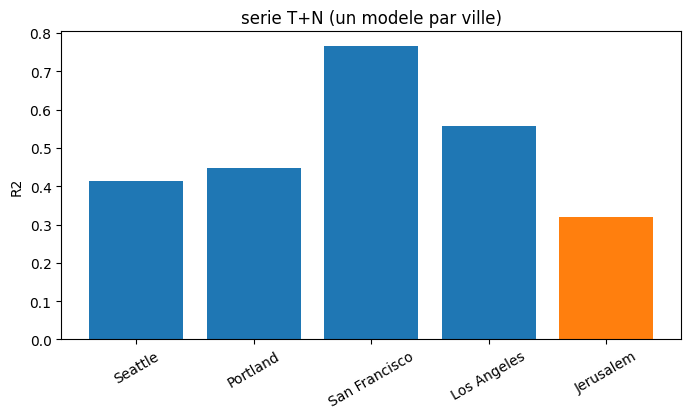

In [19]:
barres_par_ville_propre(Xrs_tr_list, yrs_tr_list, Xrs_te_list, yrs_te_list, Xrc_train, yrc_train, Xrc_test, yrc_test, "serie T+N (un modele par ville)")

## 14. normalisation par le bruit

le R2 par ville depend de la variance totale du domaine, qui differe (Jerusalem varie peu, donc son R2 s'effondre). pour comparer equitablement les villes, on rapporte l'erreur au niveau de bruit propre a chaque domaine : RMSE / sigma.

RMSE / sigma_bruit par ville (T+N) :
  Seattle : 0.64
  Portland : 0.6
  San Francisco : 0.62
  Los Angeles : 0.58
  cible (Jerusalem) : 0.72


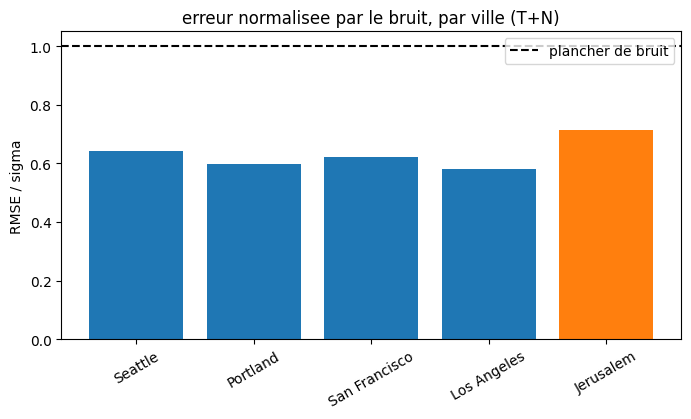

In [20]:
normes = []
print("RMSE / sigma_bruit par ville (T+N) :")
for k, ville in enumerate(source_villes):
    mse = predict("forecast", Xrs_train, yrs_train, Xrs_te_list[k], yrs_te_list[k])["mse"]
    n = np.sqrt(mse) / sigma_bruit[ville]
    normes.append(n)
    print(f"  {ville} : {round(n, 2)}")
mse_cible = predict("forecast", Xrs_train, yrs_train, Xrc_test, yrc_test)["mse"]
norme_cible = np.sqrt(mse_cible) / sigma_bruit[ville_cible]
print(f"  cible ({ville_cible}) : {round(norme_cible, 2)}")

noms = source_villes + [ville_cible]
couleurs = ["tab:blue"] * len(source_villes) + ["tab:orange"]
plt.figure(figsize=(8, 4))
plt.bar(noms, normes + [norme_cible], color=couleurs)
plt.axhline(1.0, color="k", linestyle="--", label="plancher de bruit")
plt.ylabel("RMSE / sigma")
plt.title("erreur normalisee par le bruit, par ville (T+N)")
plt.xticks(rotation=30)
plt.legend()
plt.show()

## 15. normalisation par le bruit : un modele par ville

RMSE / sigma_bruit par ville (T+N, un modele par ville) :
  Seattle : 0.61
  Portland : 0.57
  San Francisco : 0.65
  Los Angeles : 0.53
  cible (Jerusalem) : 0.59


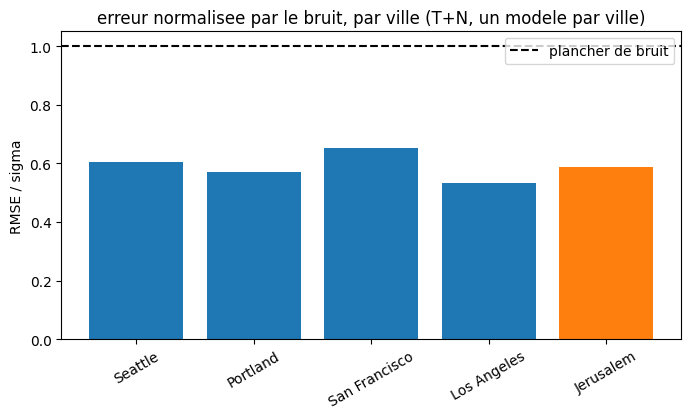

In [21]:
normes_propre = []
print("RMSE / sigma_bruit par ville (T+N, un modele par ville) :")
for k, ville in enumerate(source_villes):
    mse = predict("forecast", Xrs_tr_list[k], yrs_tr_list[k], Xrs_te_list[k], yrs_te_list[k])["mse"]
    n = np.sqrt(mse) / sigma_bruit[ville]
    normes_propre.append(n)
    print(f"  {ville} : {round(n, 2)}")
mse_cible = predict("forecast", Xrc_train, yrc_train, Xrc_test, yrc_test)["mse"]
norme_cible_propre = np.sqrt(mse_cible) / sigma_bruit[ville_cible]
print(f"  cible ({ville_cible}) : {round(norme_cible_propre, 2)}")

noms = source_villes + [ville_cible]
couleurs = ["tab:blue"] * len(source_villes) + ["tab:orange"]
plt.figure(figsize=(8, 4))
plt.bar(noms, normes_propre + [norme_cible_propre], color=couleurs)
plt.axhline(1.0, color="k", linestyle="--", label="plancher de bruit")
plt.ylabel("RMSE / sigma")
plt.title("erreur normalisee par le bruit, par ville (T+N, un modele par ville)")
plt.xticks(rotation=30)
plt.legend()
plt.show()

## 16. ADAPT


feature_based,CORAL

instance_based, KMM

parameter_based,  RegularTransferLR

temperature brute
  sans adaptation                  0.893
  CORAL (feature)                  0.821
  KMM (instance)                   0.896
  RegularTransferLR (parametre)    0.9
  cible -> cible                   0.9


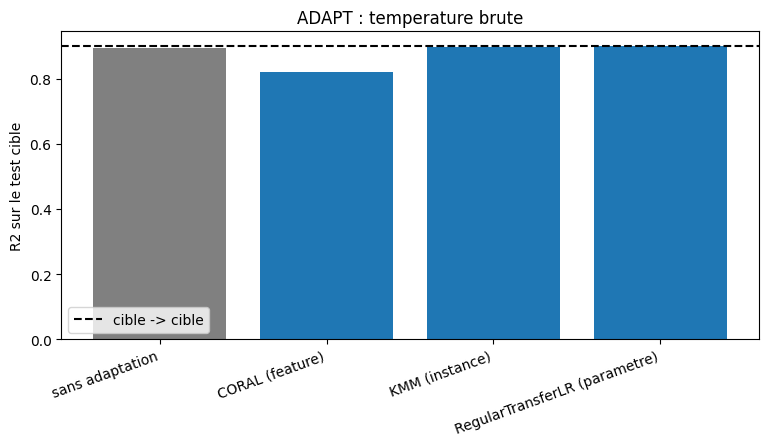

In [22]:
print("temperature brute")
res_adapt_brute = comparer_adapt("forecast", Xs_train, ys_train, Xc_train, yc_train, Xc_test, yc_test)
for k, v in res_adapt_brute.items():
    print(f"  {k:32s} {round(v, 3)}")

barres_adapt(res_adapt_brute, "ADAPT : temperature brute", "R2 sur le test cible")

serie T+N
  sans adaptation                  -0.013
  CORAL (feature)                  -1.717
  KMM (instance)                   0.139
  RegularTransferLR (parametre)    0.32
  cible -> cible                   0.32


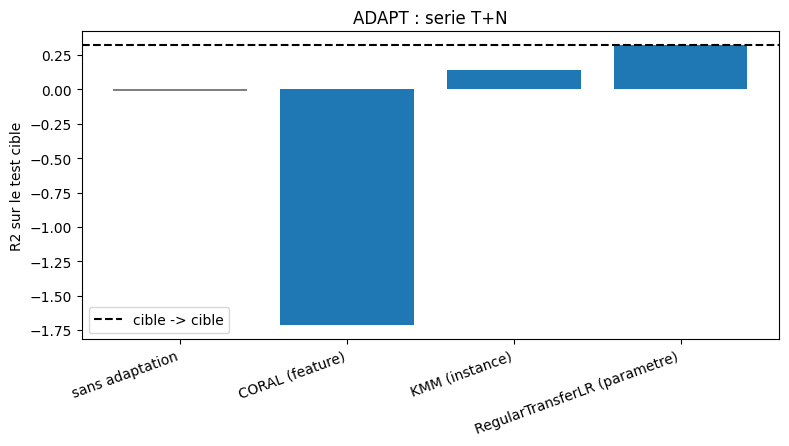

In [23]:
print("serie T+N")
res_adapt_tn = comparer_adapt("forecast", Xrs_train, yrs_train, Xrc_train, yrc_train, Xrc_test, yrc_test)
for k, v in res_adapt_tn.items():
    print(f"  {k:32s} {round(v, 3)}")

barres_adapt(res_adapt_tn, "ADAPT : serie T+N", "R2 sur le test cible")

## 17. adaptation de domaine : erreur normalisee par le bruit

  sans adaptation                  0.716
  CORAL (feature)                  1.172
  KMM (instance)                   0.66
  RegularTransferLR (parametre)    0.586
  cible -> cible                   0.586


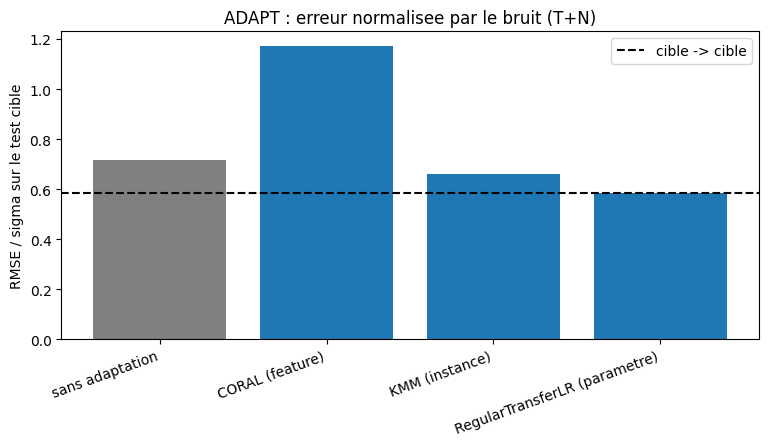

In [24]:
from sklearn.metrics import mean_squared_error

def rmse_sur_sigma(y_vrai, y_pred):
    return float(np.sqrt(mean_squared_error(y_vrai, y_pred)) / sigma_bruit[ville_cible])

res_adapt_norm = comparer_adapt("forecast", Xrs_train, yrs_train, Xrc_train, yrc_train, Xrc_test, yrc_test, score=rmse_sur_sigma)

for k, v in res_adapt_norm.items():
    print(f"  {k:32s} {round(v, 3)}")

barres_adapt(res_adapt_norm, "ADAPT : erreur normalisee par le bruit (T+N)","RMSE / sigma sur le test cible")